# Bayesian image reconstruction with NIFTy

### Summary

This notebook demonstrates **Bayesian image reconstruction** using the [NIFTy](https://gitlab.mpcdf.mpg.de/ift/nifty) framework with interferometric data from optical/infrared long-baseline interferometry. 

We explore two main reconstruction pipelines:
1. **Using complex visibilities (real + imaginary parts)**
2. **Using squared visibilities and closure phases (bispectrum)**

The notebook includes:
- Reading and preprocessing data from OIFITS files
- Constructing the measurement operator (`InterferometryResponse`)
- Defining compact prior sky models
- Building likelihoods for both visibility and bispectrum datasets
- Performing inference using **Metric Gaussian Variational Inference (MGVI)** via `ift.optimize_kl`

This notebook is part of a broader effort to use NIFTy for robust interferometric image reconstruction, with support for multiple observables and prior models.

In [1]:
#| default_exp reconstruction

In [2]:
#| export

import sys
import numpy as np
import nifty8 as ift
import ducc0.wgridder as ng
from astropy.io import fits
from finufft import nufft2d2
import matplotlib.pyplot as plt
from astropy.table import Table

import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.size': 24,             # Base font size
    'axes.titlesize': 24,        # Title font size
    'axes.labelsize': 20,        # X/Y label font size
    'xtick.labelsize': 16,       # X tick labels
    'ytick.labelsize': 16,       # Y tick labels
    'legend.fontsize': 24,  
    'lines.markersize': 14,
    'axes.linewidth':  2,
})


In [3]:
#| export
from nifty_oi.dataload import read_data
from nifty_oi import sky_models as sky
from nifty_oi.InterferometryResponse import InterferometryResponse

In [4]:
# Only the (u,v) coverage of this synthetic OIFITS file (17-telescope DEMO array) is used;
# the visibilities themselves are simulated below from a known sky.
filepath = '../data/Gaussian_elong.fits'
data     = read_data(filepath)

In [5]:
#| export
def setup_imaging_operator(data, npix=256, fov_mas=30, epsilon=1e-8):

    L, M, dx = sky.make_coordinate_grid(npix, fov_mas)
    space = ift.RGSpace((npix, npix), (dx, dx))
    im_dom = ift.makeDomain(space)

    data_m = {
        'nbl'  : data['nbl'],
        'uco'  : data['uco'].reshape(-1, 1),
        'vco'  : data['vco'].reshape(-1, 1),
        'freq' : data['freq']
    }

    response_operator = InterferometryResponse(space, data_m, epsilon, False, False)
    return space, im_dom, response_operator, dx, L, M


## `setup_imaging_operator`

Initializes the NIFTy image space and constructs the interferometric response operator that maps sky brightness distributions to observed complex visibilities.

---

### **Parameters**

| Name        | Type       | Description |
|-------------|------------|-------------|
| `data`      | `dict`     | Dictionary with interferometric data (`'nbl'`, `'uco'`, `'vco'`, `'freq'`) |
| `npix`      | `int`      | Number of image pixels along one dimension. Default: `256` |
| `fov_mas`   | `float`    | Field of view in milliarcseconds. Default: `30` |
| `epsilon`   | `float`    | Numerical stabilization factor. Default: `1e-8` |

---

### **Returns**

| Name                 | Type                     | Description |
|----------------------|--------------------------|-------------|
| `space`              | `RGSpace (NIFTy)`            | Regular 2D grid space for the image |
| `im_dom`             | `DomainTuple (NIFTy)`        | Domain created from the image space |
| `response_operator`  | `InterferometryResponse` | Operator mapping image to complex visibilities |
| `dx`                 | `float`                  | Pixel angular size in radians |
| `L`                  | `np.ndarray`             | 2D pixel coordinate grid (horizontal) in radians |
| `M`                  | `np.ndarray`             | 2D pixel coordinate grid (vertical) in radians |

---

### **Details**

#### `response_operator`
This is an instance of `InterferometryResponse` that performs the forward transform from the image domain to the visibility domain. Mathematically, it computes the Fourier transform:
$$
V(u,v) = \iint I(\ell, m) \, e^{-2\pi i(u\ell + vm)}\, d\ell\, dm
$$
where:
-  $I(\ell, m)$ $end:math:text$ is the sky brightness distribution over angular coordinates $\ell, m$ 
- $(u, v)$  are the baseline coordinates in meters
- The integral runs over the field of view in radians

This operator allows comparison of model visibilities against observed ones in the likelihood.

#### `dx`
This is the angular pixel size in **radians**, computed from the desired field of view and image resolution. 

---

### **Usage Example**

```python
space, im_dom, R, dx, L, M = setup_imaging_operator(data, npix=256, fov_mas=30)
```

In [6]:
#| export
def construct_sky_model_prior(space, im_dom, dx, model='compact_smooth_log'):

    center = np.array(space.shape) // 2
    Y, X    = np.indices(space.shape)
    r       = np.sqrt((X - center[1])**2 + (Y - center[0])**2)
    r       = r / np.max(r)

    xi = ift.FieldAdapter(space, 'xi')

    if model == 'compact_smooth_log':
        expo     = 0.01
        weight   = np.exp(-r**expo)
        weight_f = ift.Field(im_dom, val=weight)
        prior_op = ift.makeOp(weight_f)
        smoothness = 6 * dx
        smoother   = ift.HarmonicSmoothingOperator(im_dom, sigma=smoothness)
        A          = smoother @ prior_op
        sky_model  = ift.exp((A @ xi).real)

    elif model == 'correlated_field':
        args = {
            'offset_mean'   : -np.log(space.scalar_dvol) - 40.,
            'offset_std'    : (3., 1.),
            'fluctuations'  : (1.5, 0.5),
            'loglogavgslope': (-4., 0.5),
            'flexibility'   : (0.3, 0.1),
            'asperity'      : None
        }
        log_signal_raw = ift.SimpleCorrelatedField(space, **args)
        log_signal     = log_signal_raw.real
        sky_model      = ift.exp(log_signal)

    else:
        raise ValueError(f"Unknown model: {model}")

    return xi, sky_model

### `construct_sky_model_prior`

This function constructs a sky brightness prior model in interferometric imaging using NIFTy. It transforms a latent white noise field into a structured prior using spatial weighting, smoothing, and nonlinear transformations (e.g., exponential).

---

#### Parameters

| Variable   | Type              | Description |
|------------|-------------------|-------------|
| `space`    | `RGSpace (NIFTy)`     | Regular 2D grid space over which the image is defined. |
| `im_dom`   | `DomainTuple (NIFTy)` | Domain object corresponding to the image space. |
| `dx`       | `float`           | Angular pixel size in radians (used to define smoothing scale). |
| `model`    | `str`             | Specifies the type of prior to use. Options are: `'compact_smooth_log'` (default) or `'correlated_field'`. |

---

#### Returns

| Variable     | Type               | Description |
|--------------|--------------------|-------------|
| `xi`         | `FieldAdapter (NIFTy)` | Latent white noise field. |
| `sky_model`  | `Operator (NIFTy)`     | Sky brightness prior constructed from `xi`. |

---

### Details of `'compact_smooth_log'` Prior

This model creates a sky prior with radial compactness and smoothness. The construction follows:

$$
s = \exp\left( A \cdot \xi \right)
$$

- $\xi$: Latent white noise field over the image space.  
- $A$: Composition of a diagonal radial weight operator and a harmonic smoothing operator.  
- The radial weight is given by:

$$
w(r) = \exp(-r^{\alpha})
$$

where $r$ is the normalized radial distance from the image center, and $\alpha$ is a small positive constant (e.g., 0.01).

- The smoother is a harmonic smoothing operator with scale $\sigma = 6 \cdot dx$.

---

### Usage Example
```python
xi, sky_model = construct_sky_model_prior(space, im_dom, dx, model='compact_smooth_log')
```

In [7]:
#| export
def compute_model_bispectrum(sky_model, space, data, epsilon=1e-8):

    data1 = {
        'nbl'  : data['ncl'],
        'uco'  : data['ut3'][0, :, 0].reshape(1, -1),
        'vco'  : data['vt3'][0, :, 0].reshape(1, -1),
        'freq' : data['freq']
    }
    data2 = {
        'nbl'  : data['ncl'],
        'uco'  : data['ut3'][0, :, 1].reshape(1, -1),
        'vco'  : data['vt3'][0, :, 1].reshape(1, -1),
        'freq' : data['freq']
    }
    data3 = {
        'nbl'  : data['ncl'],
        'uco'  : data['ut3'][0, :, 2].reshape(1, -1),
        'vco'  : data['vt3'][0, :, 2].reshape(1, -1),
        'freq' : data['freq']
    }

    r_op1 = InterferometryResponse(space, data1, epsilon, False, False)
    r_op2 = InterferometryResponse(space, data2, epsilon, False, False)
    r_op3 = InterferometryResponse(space, data3, epsilon, False, False)

    vis1 = r_op1 @ sky_model
    vis2 = r_op2 @ sky_model
    vis3 = r_op3 @ sky_model

    bisp_model = vis1 * vis2 * vis3.conjugate()
    return bisp_model, r_op1, r_op2, r_op3



### `compute_model_bispectrum`

Computes the **complex bispectrum model** (closure phase observable) by evaluating visibilities on three baselines forming a triangle, and returning the triple product:

$$
B = V_{12} \cdot V_{23} \cdot V_{31}^*
$$

---

#### Parameters

| Variable   | Type              | Description |
|------------|-------------------|-------------|
| `sky_model` | `Operator (NIFTy)`| Sky brightness distribution (field or prior operator). |
| `space`     | `RGSpace  (NIFTy)`              | NIFTy regular grid over the image domain. |
| `data`      | `dict`                     | Observational data dictionary with triangle baseline info. Must contain: `ut3`, `vt3`, `freq`, `ncl`. |
| `epsilon`   | `float`, optional          | Stabilization constant used in constructing the response operators (default = 1e-8). |

---

#### Returns

| Variable     | Type         | Description |
|--------------|--------------|-------------|
| `bisp_model` | `Field  (NIFTy)`  | Modeled bispectrum computed as $V_{12} \cdot V_{23} \cdot V_{31}^*$. |
| `r_op1`      | `Operator`   | Response operator for baseline 1 of triangle. |
| `r_op2`      | `Operator`   | Response operator for baseline 2. |
| `r_op3`      | `Operator`   | Response operator for baseline 3. |

---

### Mathematical Description

Given a sky model $s(x)$ and three baselines forming a triangle, the **bispectrum** is computed as:

$$
B = V(u_1, v_1) \cdot V(u_2, v_2) \cdot V(u_3, v_3)^*
$$

where $V(u, v)$ is the Fourier transform of the sky intensity at baseline $(u, v)$.

Each visibility is computed using the `InterferometryResponse` operator over the image space.

---

### Usage Example

```python

bisp_model, r_op1, r_op2, r_op3 = compute_model_bispectrum( sky_model, space, data, epsilon=1e-8 )


```

In [8]:
#| export
def simulate_data1(data, L, M, dx, npix, r_op1, r_op2, r_op3,model='compact_smooth_log'):

    epsilon = 1e-8
    space = ift.RGSpace((npix, npix), (dx, dx))
    im_dom = ift.makeDomain(space)
    center = np.array(space.shape) // 2
    Y, X    = np.indices(space.shape)
    r       = np.sqrt((X - center[1])**2 + (Y - center[0])**2)
    r       = r / np.max(r)

    xi = ift.FieldAdapter(space, 'xi')

    if model == 'compact_smooth_log':
        expo     = 0.01
        weight   = np.exp(-r**expo)
        weight_f = ift.Field(im_dom, val=weight)
        prior_op = ift.makeOp(weight_f)
        smoothness = 6 * dx
        smoother   = ift.HarmonicSmoothingOperator(im_dom, sigma=smoothness)
        A          = smoother @ prior_op
        sky_model  = ift.exp((A @ xi).real)

    elif model == 'correlated_field':
        args = {
            'offset_mean'   : -np.log(space.scalar_dvol) - 40.,
            'offset_std'    : (3., 1.),
            'fluctuations'  : (1.5, 0.5),
            'loglogavgslope': (-4., 0.5),
            'flexibility'   : (0.3, 0.1),
            'asperity'      : None
        }
        log_signal_raw = ift.SimpleCorrelatedField(space, **args)
        log_signal     = log_signal_raw.real
        sky_model      = ift.exp(log_signal)

    else:
        raise ValueError(f"Unknown model: {model}")

    mock = ift.from_random(sky_model.domain)
    sky_dist = sky_model(mock)
    im_field = ift.Field(im_dom, val=sky_dist.val)

    data_m = {
        'nbl': data['nbl'],
        'uco': data['uco'].reshape(-1, 1),
        'vco': data['vco'].reshape(-1, 1),
        'freq': data['freq']
    }
    response_operator = InterferometryResponse(space, data_m, epsilon, False,False)
    vis_data = response_operator(im_field).val
    vis2_data = vis_data * vis_data.conjugate()

    vis1_d = r_op1(im_field)
    vis2_d = r_op2(im_field)
    vis3_d = r_op3(im_field)
    bisp_data = (vis1_d * vis2_d * vis3_d.conjugate()).val

    return sky_dist, vis_data, vis2_data, bisp_data, im_field

In [9]:
#| export
def simulate_data(data, L, M, dx, npix, r_op1, r_op2, r_op3):

    epsilon = 1e-8
    space = ift.RGSpace((npix, npix), (dx, dx))
    im_dom = ift.makeDomain(space)

    # Create composite sky model
    d1 = sky.make_disk(L, M, 2, x0_mas=-8.0, y0_mas=8.0)
    r1 = sky.make_ring(L, M, inner_mas=2, outer_mas=3, x0_mas=4, y0_mas=6)
    sky_dist = 0.3 * r1 + 0.7 * d1

    im_field = ift.Field(im_dom, val=sky_dist)

    data_m = {
        'nbl': data['nbl'],
        'uco': data['uco'].reshape(-1, 1),
        'vco': data['vco'].reshape(-1, 1),
        'freq': data['freq']
    }
    response_operator = InterferometryResponse(space, data_m, epsilon, False)
    vis_data = response_operator(im_field).val
    vis2_data = vis_data * vis_data.conjugate()

    vis1_d = r_op1(im_field)
    vis2_d = r_op2(im_field)
    vis3_d = r_op3(im_field)
    bisp_data = (vis1_d * vis2_d * vis3_d.conjugate()).val

    return sky_dist, vis_data, vis2_data, bisp_data, im_field

### `simulate_data`

Simulates a synthetic sky brightness distribution using simple geometric components (disk and ring), and computes corresponding interferometric observables: complex visibilities, squared visibilities, and bispectrum.

---

#### Parameters

| Variable    | Type                   | Description |
|-------------|------------------------|-------------|
| `data`      | `dict`                 | Observational baseline and frequency data. Must include: `uco`, `vco`, `freq`, and `nbl`. |
| `L`, `M`    | `np.ndarray`           | Coordinate grids (in radians) over the image domain. |
| `dx`        | `float`                | Angular pixel size in radians. |
| `npix`      | `int`                  | Number of pixels per side in the image. |
| `r_op1`     | `InterferometryResponse` | Response operator for baseline 1 of a triangle. |
| `r_op2`     | `InterferometryResponse` | Response operator for baseline 2. |
| `r_op3`     | `InterferometryResponse` | Response operator for baseline 3. |

---

#### Returns

| Variable     | Type         | Description |
|--------------|--------------|-------------|
| `sky_dist`   | `np.ndarray` | 2D array of simulated sky brightness (disk + ring). |
| `vis_data`   | `np.ndarray` | Complex visibilities computed from the sky model. |
| `vis2_data`  | `np.ndarray` | Squared visibility amplitudes: $|V|^2$. |
| `bisp_data`  | `np.ndarray` | Complex bispectrum: $V_1 \cdot V_2 \cdot V_3^*$. |
| `im_field`   | `ift.Field`  | NIFTy field containing the ground-truth sky distribution. |

---

### Sky Model

The simulated sky is created using:

$$
\text{sky\_dist}(x, y) = a \cdot \text{ring}(x, y) + b \cdot \text{disk}(x_1, y_1)
$$

- The **disk** is centered at $(x, y)$
- The **ring** is centered at $(x_1, y_1)$

---

### Usage Example

```python
sky_dist, vis_data, vis2_data, bisp_data, im_field = simulate_data(data, L, M, dx, npix, r_op1, r_op2, r_op3)

plt.imshow(sky_dist, origin='lower')
plt.title("Simulated Sky Brightness")
plt.colorbar()
plt.show()
```

In [10]:
#| export
def build_complex_visibility_likelihood(vis_data, data, response_operator, sky_model):

    vis_data = vis_data.reshape((data['nbl'], 1))  # Reshape to column vector
    domain = ift.DomainTuple.make([ift.UnstructuredDomain((data['nbl'], 1))])
    vis_dataf = ift.Field(domain, val=vis_data)

    # Use uniform large weights (i.e., low noise)
    weights = np.ones((data['nbl'], 1), dtype=np.float64) * 1e6
    weights = ift.Field(domain, val=weights)

    inverse_covariance = ift.DiagonalOperator(weights, sampling_dtype=vis_dataf.dtype)

    likelihood = ift.GaussianEnergy(
        data=vis_dataf,
        inverse_covariance=inverse_covariance
    )

    likelihood_viscmplx = likelihood @ response_operator @ sky_model
    return likelihood_viscmplx

### `build_complex_visibility_likelihood`

Constructs the **Gaussian likelihood** operator for complex interferometric visibilities.  
This is useful when the visibility data (both amplitude and phase) is directly available and assumed to follow a Gaussian noise model.

---

#### Parameters

| Parameter          | Type                | Description |
|--------------------|---------------------|-------------|
| `vis_data`         | `np.ndarray`        | Measured complex visibilities of shape `(nbl,)`. These represent $V(u,v)$ data. |
| `data`             | `dict`              | Dictionary containing interferometric observation metadata, including `'nbl'` (number of baselines). |
| `response_operator`| `ift.Operator`      | Interferometric forward operator mapping sky image $\rightarrow$ model visibilities. |
| `sky_model`        | `ift.Operator`      | Prior model representing the sky brightness distribution. |

---

#### Returns

| Return Value         | Type           | Description |
|----------------------|----------------|-------------|
| `likelihood_viscmplx`| `ift.Operator` | Likelihood operator representing $- \log \mathcal{L}(V_{\text{data}} \mid \text{sky})$ where visibilities follow a Gaussian model. |

---

### Mathematical Formulation

This function implements the Gaussian log-likelihood energy:

$$
\mathcal{H}_{\text{likelihood}} = \frac{1}{2} \left(V_{\text{data}} - R[\rho]\right)^\dagger N^{-1} \left(V_{\text{data}} - R[\rho]\right)
$$

Where:

- $V_{\text{data}}$ are the measured complex visibilities
- $R[\rho]$ is the forward model (i.e., the predicted visibilities from the sky model)
- $N$ is the noise covariance (diagonal here with inverse weights $\propto 10^6$ for low noise)

> Note: This assumes all visibilities are equally weighted with very small noise (i.e., large inverse variance $10^6$).

---

### Usage Example

```python
likelihood_viscmplx = build_complex_visibility_likelihood(
    vis_data=vis_data,
    data=data,
    response_operator=response_operator,
    sky_model=sky_model
)
```

You can now use `likelihood_viscmplx` in your inference loop or to build the total Hamiltonian with other likelihood terms.

In [11]:
#| export
def build_squared_visibility_likelihood(vis2_data, response_operator, sky_model, data, sigma_vis2=0.001):

    # Compute model squared visibilities
    vis_complex = response_operator @ sky_model
    vis_squared = (vis_complex * vis_complex.conjugate()).real

    # Add noise to observed vis² data
    vis2_amp   = vis2_data.ravel().real
    vis2_noisy = vis2_amp + np.random.normal(0, sigma_vis2, size=vis2_amp.shape)

    # Prepare vis² data and error
    vis2_data = vis2_noisy.reshape((data['nbl'], 1)).astype(np.float64)
    vis2_err  = np.full_like(vis2_data, sigma_vis2)
    weights_vis2 = 1. / (vis2_err**2)
    weights_vis2 = np.clip(weights_vis2, 1e-6, np.inf)  # Avoid zeros

    # NIFTy domain for vis² data
    vis2_domain = ift.DomainTuple.make([ift.UnstructuredDomain((data['nbl'], 1))])

    # Wrap into NIFTy Fields
    weights_vis2 = ift.Field(vis2_domain, val=weights_vis2)
    vis2_field   = ift.Field(vis2_domain, val=vis2_data)

    # Diagonal noise covariance operator
    inverse_covariance = ift.DiagonalOperator(weights_vis2, sampling_dtype=vis2_data.dtype)

    # Gaussian likelihood
    likelihood_vis2 = ift.GaussianEnergy(data=vis2_field, inverse_covariance=inverse_covariance)
    likelihood_vis2 = likelihood_vis2 @ vis_squared

    return likelihood_vis2

### `build_squared_visibility_likelihood`

Constructs the **Gaussian likelihood** operator for **squared visibilities** ($|V|^2$), commonly used in optical interferometry when complex phases are unreliable or unavailable.

---

#### Parameters

| Parameter            | Type            | Description |
|----------------------|-----------------|-------------|
| `vis2_data`          | `np.ndarray`    | Observed squared visibilities of shape `(nbl,)`. |
| `response_operator`  | `ift.Operator`  | Operator mapping the sky brightness distribution to complex visibilities. |
| `sky_model`          | `ift.Operator`  | Sky model operator, typically exponential of smoothed white noise field. |
| `data`               | `dict`          | Dictionary containing observational metadata, including `'nbl'` (number of baselines). |
| `sigma_vis2`         | `float`         | Standard deviation of assumed Gaussian noise on vis² (default = 0.001). |

---

#### Returns

| Return Value        | Type           | Description |
|---------------------|----------------|-------------|
| `likelihood_vis2`   | `ift.Operator` | Log-likelihood energy operator based on squared visibility amplitudes. |

---

### Mathematical Formulation

This function implements a **Gaussian energy** functional for squared visibilities:

$$
\mathcal{H}_{|V|^2} = \frac{1}{2} \sum_i \frac{ \left( |V_i|^2_{\text{data}} - |V_i|^2_{\text{model}} \right)^2 }{ \sigma_i^2 }
$$

Where:
- $|V_i|^2_{\text{data}}$ is the measured squared visibility for baseline $i$.
- $|V_i|^2_{\text{model}} = \text{Re}(V_i \cdot V_i^*)$ is the modeled squared visibility.
- $\sigma_i^2$ is the assumed variance (here uniform).

---

### Implementation Notes

- Adds simulated Gaussian noise to vis² data (`vis2_noisy`) using `sigma_vis2`.
- Wraps the data and inverse covariance matrix into NIFTy `Field` and `DiagonalOperator`.
- Composes the likelihood operator:  
  $$ \text{likelihood} = \mathcal{H}( |V|^2_{\text{model}} ) $$

---

### Usage Example

```python
likelihood_vis2 = build_squared_visibility_likelihood(
    vis2_data=vis2_data,
    response_operator=response_operator,
    sky_model=sky_model,
    data=data,
    sigma_vis2=0.001
)
```

This likelihood can now be combined with other likelihoods (e.g., complex visibility or bispectrum) in a total energy functional for inference.

In [12]:
#| export
def build_bispectrum_likelihood(data, bisp_data, bisp_model, sigma_b_amp=0.0002, sigma_b_phase=0.0005):


    # --- Define domain for bispectrum ---
    vist3_domain = ift.DomainTuple.make([ift.UnstructuredDomain((data['ncl'], 1))])

    # --- Add noise to bispectrum ---
    bisp = bisp_data.ravel()
    noise_b_re = np.random.normal(0, sigma_b_amp, size=bisp.shape)
    noise_b_im = np.random.normal(0, sigma_b_phase, size=bisp.shape)
    bisp_noisy = bisp + noise_b_re + 1j * noise_b_im

    # --- Prepare likelihood input ---
    bisp_d = bisp_noisy.reshape((data['ncl'], 1)).astype(np.complex128)
    bisp_err = np.full((data['ncl'], 1), sigma_b_amp)
    weights_bisp = 1. / (bisp_err**2)
    weights_bisp = np.clip(weights_bisp, 1e-6, np.inf)

    # --- Wrap into NIFTy objects ---
    bisp_field = ift.Field(vist3_domain, val=bisp_d)
    weights_vis3 = ift.Field(vist3_domain, val=weights_bisp)
    inverse_covariance3 = ift.DiagonalOperator(weights_vis3, sampling_dtype=bisp_d.dtype)

    # --- Construct likelihood operator ---
    likelihood_bisp = ift.GaussianEnergy(
        data = bisp_field,
        inverse_covariance = inverse_covariance3
    )
    likelihood_bisp = likelihood_bisp @ bisp_model                # Likelihood operator for bispectrum data

    return likelihood_bisp

### `build_bispectrum_likelihood`

Constructs a **Gaussian likelihood** operator based on the **bispectrum**, which is the triple product of complex visibilities across a closed triangle of baselines. This is a key observable in optical interferometry that is phase-invariant and robust to certain atmospheric distortions.

---

#### Parameters

| Parameter        | Type            | Description |
|------------------|-----------------|-------------|
| `data`           | `dict`          | OIFITS-style data dictionary with `'ncl'` (number of closure triangles). |
| `bisp_data`      | `np.ndarray`    | Observed bispectrum data, shape `(ncl,)`, complex-valued. |
| `bisp_model`     | `ift.Operator`  | Model bispectrum operator that returns modeled closure phases. |
| `sigma_b_amp`    | `float`         | Standard deviation of noise added to bispectrum real part (default: 0.0002). |
| `sigma_b_phase`  | `float`         | Standard deviation of noise added to bispectrum imaginary part (default: 0.0005). |

---

#### Returns

| Return Value     | Type            | Description |
|------------------|-----------------|-------------|
| `likelihood_bisp`| `ift.Operator`  | Final Gaussian energy operator acting on the modeled bispectrum. |

---

### Mathematical Formulation

This function builds the following log-likelihood energy:

$$
\mathcal{H}_{B} = \frac{1}{2} \sum_i \frac{ \left| B_i^{\text{data}} - B_i^{\text{model}} \right|^2 }{ \sigma_i^2 }
$$

Where:
- $B_i^{\text{data}}$ is the complex bispectrum for triangle $i$,
- $B_i^{\text{model}}$ is the modeled bispectrum:  
  $$ B_i = V_{ij} V_{jk} V_{ki}^* $$
- $\sigma_i^2$ is the assumed (uniform) noise variance on the bispectrum.

---

### Implementation Notes

- Adds **Gaussian noise** separately to real and imaginary parts of the input bispectrum data.
- Uses a **complex-valued diagonal covariance** for the likelihood (real weights, complex-valued data).
- The modeled bispectrum `bisp_model` is a composition of response operators applied to the sky brightness field.

---

### Usage Example

```python
likelihood_bisp = build_bispectrum_likelihood(
    data=data,
    bisp_data=bisp_data,
    bisp_model=bisp_model,
    sigma_b_amp=0.0002,
    sigma_b_phase=0.0005
)
```

This operator can be added to the total log-likelihood in a Bayesian inference pipeline combining visibilities, vis², and bispectrum data.

In [13]:
from IPython.display import clear_output

def _imshow(figure, field, ax, title, vmin = 0, vmax = None, cmap='afmhot',fov_mas=30):
    extent = [-fov_mas/2, fov_mas/2, -fov_mas/2, fov_mas/2]
    im0 = ax.imshow(np.abs(field.val.T), origin = 'lower', cmap=cmap,extent=extent)
    figure.colorbar(im0, ax=ax, shrink=0.45)
    ax.set_xlabel(r'x $\left(m as\right)$')
    ax.set_ylabel(r'y $\left(m as\right)$')
    ax.set_title(title)

def plotting_callback(samples):
    clear_output(wait=True)    

    sky_mean, sky_var = samples.sample_stat(sky_model)
    fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(15,13))
    axs = axs.flatten()

    _imshow(fig, sky_mean, axs[0], 'Sky brightness mean')
    _imshow(fig, sky_var, axs[1], 'Std dev')
    fig.tight_layout()  
    plt.show()

In [14]:
#| export
def run_mgvi_inference(
    likelihood_operator,
    sky_model,
    output_directory,
    n_iterations=1,
    seed=0,
    inspect_callback = None):
    """
    Runs MGVI inference using KL minimization on the provided likelihood operator.

    Parameters
    ----------
    likelihood_operator : ift.Operator
        The full likelihood operator, e.g. `likelihood_bisp`, `likelihood_viscmplx`, or `likelihood_vis2`.
    sky_model : ift.Operator
        The sky model operator.
    im_field : ift.Field
        Initial image field used to initialize the optimization.
    output_directory : str
        Path to directory where logs and results will be saved.
    n_iterations : int, optional
        Number of KL optimization iterations. Default is 1.
    seed : int, optional
        Seed for random initialization. Default is 0.

    Returns
    -------
    samples : list
        List of posterior samples and final MAP estimate returned by `ift.optimize_kl`.
    """
    np.random.seed(seed)

    # --- Controllers for convergence ---
    ic_sampling     = ift.AbsDeltaEnergyController(deltaE=0.005, iteration_limit=10)
    ic_sampling_nl  = ift.AbsDeltaEnergyController(deltaE=0.005, iteration_limit=10, convergence_level=1)
    ic_newton_early = ift.AbsDeltaEnergyController(name='Newton', deltaE=0.001, iteration_limit=10, convergence_level=1)
    ic_newton_late  = ift.AbsDeltaEnergyController(name='Newton', deltaE=0.001, iteration_limit=10, convergence_level=1)

    # --- Optimizers ---
    minimizer_early = ift.NewtonCG(ic_newton_early)
    minimizer_late  = ift.NewtonCG(ic_newton_late)

    # --- Sample schedule ---
    n_samples = lambda iiter: 2 if iiter < 5 else 4
    minimizer = lambda iiter: minimizer_early if iiter < 10 else minimizer_late
    minimizer_sampling = lambda iiter: None if iiter < 10 else ift.NewtonCG(ic_sampling_nl)

    # --- Initial position ---
    initial_position = (ift.from_random(sky_model.domain, 'normal') * 0.0).real

    # --- Run inference ---
    samples = ift.optimize_kl(
        likelihood_operator,
        n_iterations,
        n_samples,
        minimizer,
        ic_sampling,
        minimizer_sampling,
        initial_position=initial_position,
        inspect_callback=inspect_callback,
        plot_energy_history=True,
        plot_minisanity_history=True,
        save_strategy='last',
        return_final_position=True,
        output_directory=output_directory
    )

    return samples

In [15]:
space, im_dom, response_operator, dx, L, M =  setup_imaging_operator(data, npix=128, fov_mas=30, epsilon=1e-8)
xi, sky_model = construct_sky_model_prior(space, im_dom, dx, model='compact_smooth_log')
bisp_model, r_op1, r_op2, r_op3 = compute_model_bispectrum(sky_model, space, data)
sky_dist, vis_data, vis2_data, bisp_data, im_field = simulate_data(data, L, M, dx, 128, r_op1, r_op2, r_op3)
#sky_dist, vis_data, vis2_data, bisp_data, im_field = simulate_data1(data, L, M, dx, 128, r_op1, r_op2, r_op3,model='correlated_field')


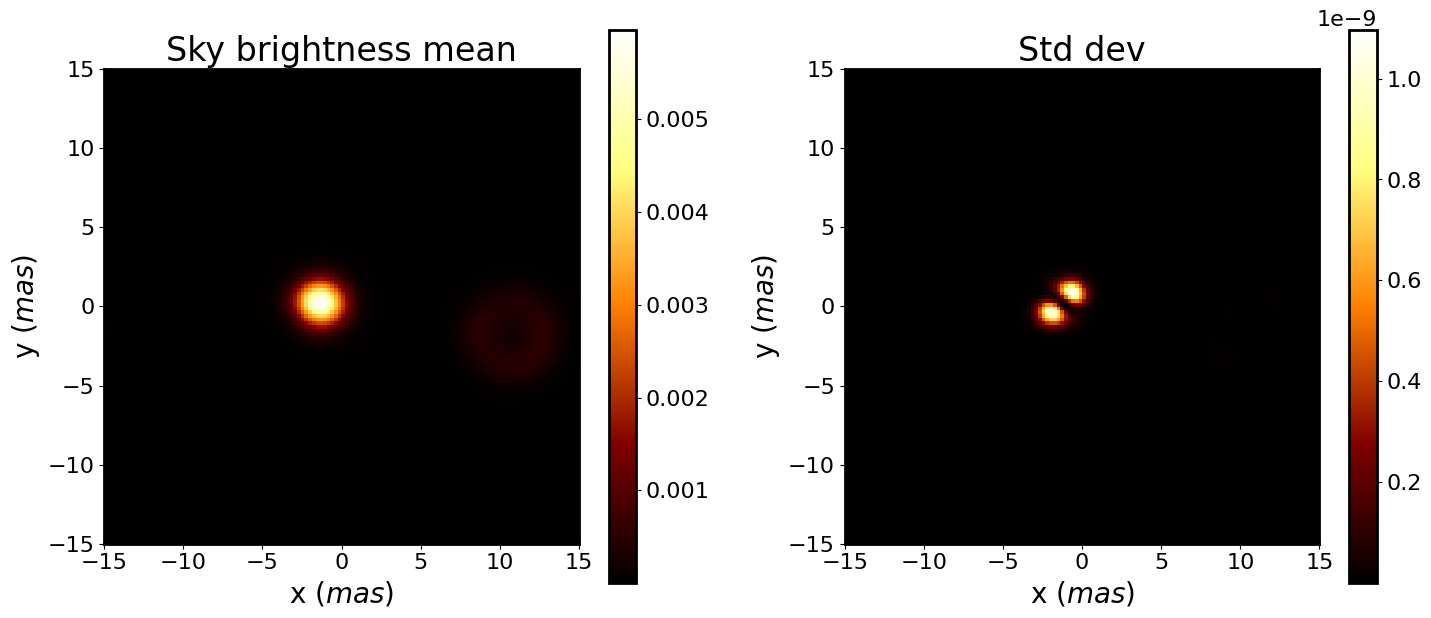

In [16]:
likelihood_viscmplx = build_complex_visibility_likelihood(vis_data, data, response_operator, sky_model)
likelihood_vis2 = build_squared_visibility_likelihood(vis2_data, response_operator, sky_model, data,sigma_vis2=0.001)
likelihood_bisp = build_bispectrum_likelihood(data, bisp_data, bisp_model,sigma_b_amp=0.002, sigma_b_phase=0.005)
# --- Combine individual likelihood terms into total likelihood ---

# likelihood_vis2        → Likelihood for squared visibilities (|V|²)
# likelihood_bisp        → Likelihood for bispectrum (closure phase data)
directory = 'results'  # MGVI output (energy history, samples)

likelihood_vis2_bispec = likelihood_vis2 + likelihood_bisp  # Total likelihood combining vis² and bispectrum
samples  = run_mgvi_inference(likelihood_vis2_bispec,sky_model,directory,n_iterations=10,seed=0,inspect_callback = plotting_callback)


### Truth vs posterior

|V|² and closure phases are invariant to a translation of the image, so the absolute position of the
source is not constrained by the data — only the relative layout is. Below, the posterior mean is
shifted so that its photocentre matches that of the truth before comparing.

posterior mean shifted by [-5.83  7.76] mas (x, y)


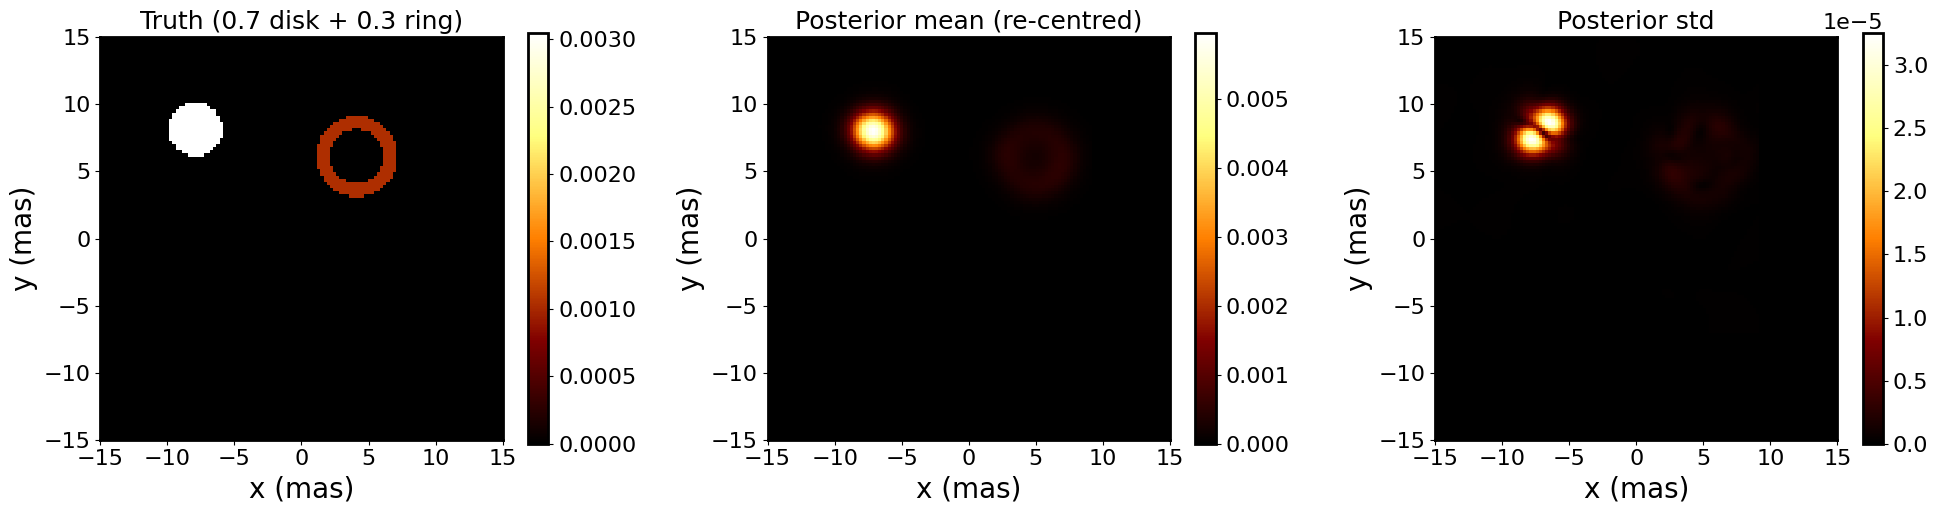

In [17]:
from scipy.ndimage import shift as nd_shift

sample_list, _ = samples
sky_mean, sky_var = sample_list.sample_stat(sky_model)
mean_img, std_img = sky_mean.val, np.sqrt(sky_var.val)

def photocentre(img):
    ii, jj = np.indices(img.shape)
    return np.array([(ii * img).sum(), (jj * img).sum()]) / img.sum()

offset = photocentre(sky_dist) - photocentre(mean_img)  # in pixels
fov_pix_mas = 30 / 128
mean_aligned = nd_shift(mean_img, offset, order=1)
std_aligned  = nd_shift(std_img, offset, order=1)
print(f"posterior mean shifted by {np.round(offset * fov_pix_mas, 2)} mas (x, y)")

fov = 30
ext = [-fov/2, fov/2, -fov/2, fov/2]
fig, axs = plt.subplots(1, 3, figsize=(20, 6))
for ax, img, title in zip(axs, [sky_dist, mean_aligned, std_aligned],
                          ['Truth (0.7 disk + 0.3 ring)', 'Posterior mean (re-centred)', 'Posterior std']):
    im = ax.imshow(img.T, origin='lower', extent=ext, cmap='afmhot')
    fig.colorbar(im, ax=ax, shrink=0.8)
    ax.set_title(title, fontsize=18); ax.set_xlabel('x (mas)'); ax.set_ylabel('y (mas)')
fig.tight_layout()
plt.show()

In [18]:
#| export
def plot_model_vs_data(samples, sky_model, response_operator, vis_data, vis2_data, bisp_data, r_op1, r_op2, r_op3, data, vis2_err, bisp_err, num2=50):
    
    sample_list, final_position = samples
    sky_mean, sky_var = sample_list.sample_stat(sky_model)
    vis2_f = response_operator(sky_mean)
    vis_squared = (vis2_f * vis2_f.conjugate()).real

    vis_b1 = r_op1(sky_mean)
    vis_b2 = r_op2(sky_mean)
    vis_b3 = r_op3(sky_mean)
    bisp_model_1 = vis_b1 * vis_b2 * vis_b3.conjugate()

    # Closure triangle baselines
    u1, v1 = data['ut3'][0, :, 0], data['vt3'][0, :, 0]
    u2, v2 = data['ut3'][0, :, 1], data['vt3'][0, :, 1]
    u3, v3 = data['ut3'][0, :, 2], data['vt3'][0, :, 2]
    bl1 = np.sqrt(u1**2 + v1**2)
    bl2 = np.sqrt(u2**2 + v2**2)
    bl3 = np.sqrt(u3**2 + v3**2)
    max_baselines = np.max(np.stack([bl1, bl2, bl3], axis=0), axis=0)

    bisp_sort_idx = np.argsort(max_baselines)
    bisp_sorted_baseline = max_baselines[bisp_sort_idx]
    bisp_model_sorted = bisp_model_1.val[bisp_sort_idx].ravel()
    bisp_data_sorted = bisp_data[bisp_sort_idx].ravel()
    bisp_err_sorted  = bisp_err[bisp_sort_idx].ravel()

    u = data['uco']
    v = data['vco']
    sort_idx = np.argsort(u)
    u_sorted = u[0, sort_idx]
    v_sorted = v[0, sort_idx]
    vis_sorted = vis_data[sort_idx].ravel()
    baseline = np.sqrt(u_sorted**2 + v_sorted**2).ravel()

    vis_r = response_operator(sky_mean).val
    vis_r = vis_r[sort_idx].ravel()

    baseline_vis = np.sqrt(data['uco'][0]**2 + data['vco'][0]**2)
    vis2_sort_idx = np.argsort(baseline_vis)
    baseline_vis_sorted = baseline_vis[vis2_sort_idx]
    vis2_data_sorted = vis2_data[vis2_sort_idx].ravel()
    vis2_model_sorted = vis_squared.val[vis2_sort_idx].ravel()
    vis2_err_sorted = vis2_err[vis2_sort_idx].ravel()

    # Plotting
    fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(25, 18))
    axs = axs.flatten()

    # --- |V|
    axs[0].plot(baseline[::num2], np.abs(vis_r[::num2]), 'o', label='Reconstructed')
    axs[0].plot(baseline[::num2], np.abs(vis_sorted[::num2]), '*', label='Data')
    axs[0].set_ylabel('|V|')
    axs[0].set_xlabel('Baseline')
    axs[0].set_title('Visibilities (|V|)')
    axs[0].legend()
    axs[0].grid()

    # --- |V|² with error bars
    axs[1].plot(baseline_vis_sorted[::num2], np.abs(vis2_model_sorted[::num2]), 'o', label='Reconstructed')
    axs[1].errorbar(baseline_vis_sorted[::num2], np.abs(vis2_data_sorted[::num2]), 
                    yerr=vis2_err_sorted[::num2], fmt='*', ecolor='gray', capsize=3, label='Data')
    axs[1].set_ylabel('Amplitude')
    axs[1].set_xlabel('Baseline Length')
    axs[1].set_title('Vis2 (|V|²)')
    axs[1].legend()
    axs[1].grid()

    # --- |B| with error bars
    axs[2].plot(bisp_sorted_baseline[::num2], np.abs(bisp_model_sorted[::num2]), 'o', label='Reconstructed')
    axs[2].errorbar(bisp_sorted_baseline[::num2], np.abs(bisp_data_sorted[::num2]), 
                    yerr=bisp_err_sorted[::num2], fmt='*', ecolor='gray', capsize=3, label='Data')
    axs[2].set_ylabel('Amplitude')
    axs[2].set_xlabel('Max Baseline per Triangle')
    axs[2].set_title('Amplitude of Bispectrum')
    axs[2].legend()
    axs[2].grid()

    # --- ∠B (no error bars typically)
    axs[3].plot(bisp_sorted_baseline[::num2], np.angle(bisp_model_sorted[::num2]), 'o', label='Reconstructed')
    axs[3].plot(bisp_sorted_baseline[::num2], np.angle(bisp_data_sorted[::num2]), '*', label='Data')
    axs[3].set_ylabel('Phase')
    axs[3].set_xlabel('Max Baseline per Triangle')
    axs[3].set_title('Angle of Bispectrum')
    axs[3].legend()
    axs[3].grid()

    plt.tight_layout()
    plt.show()

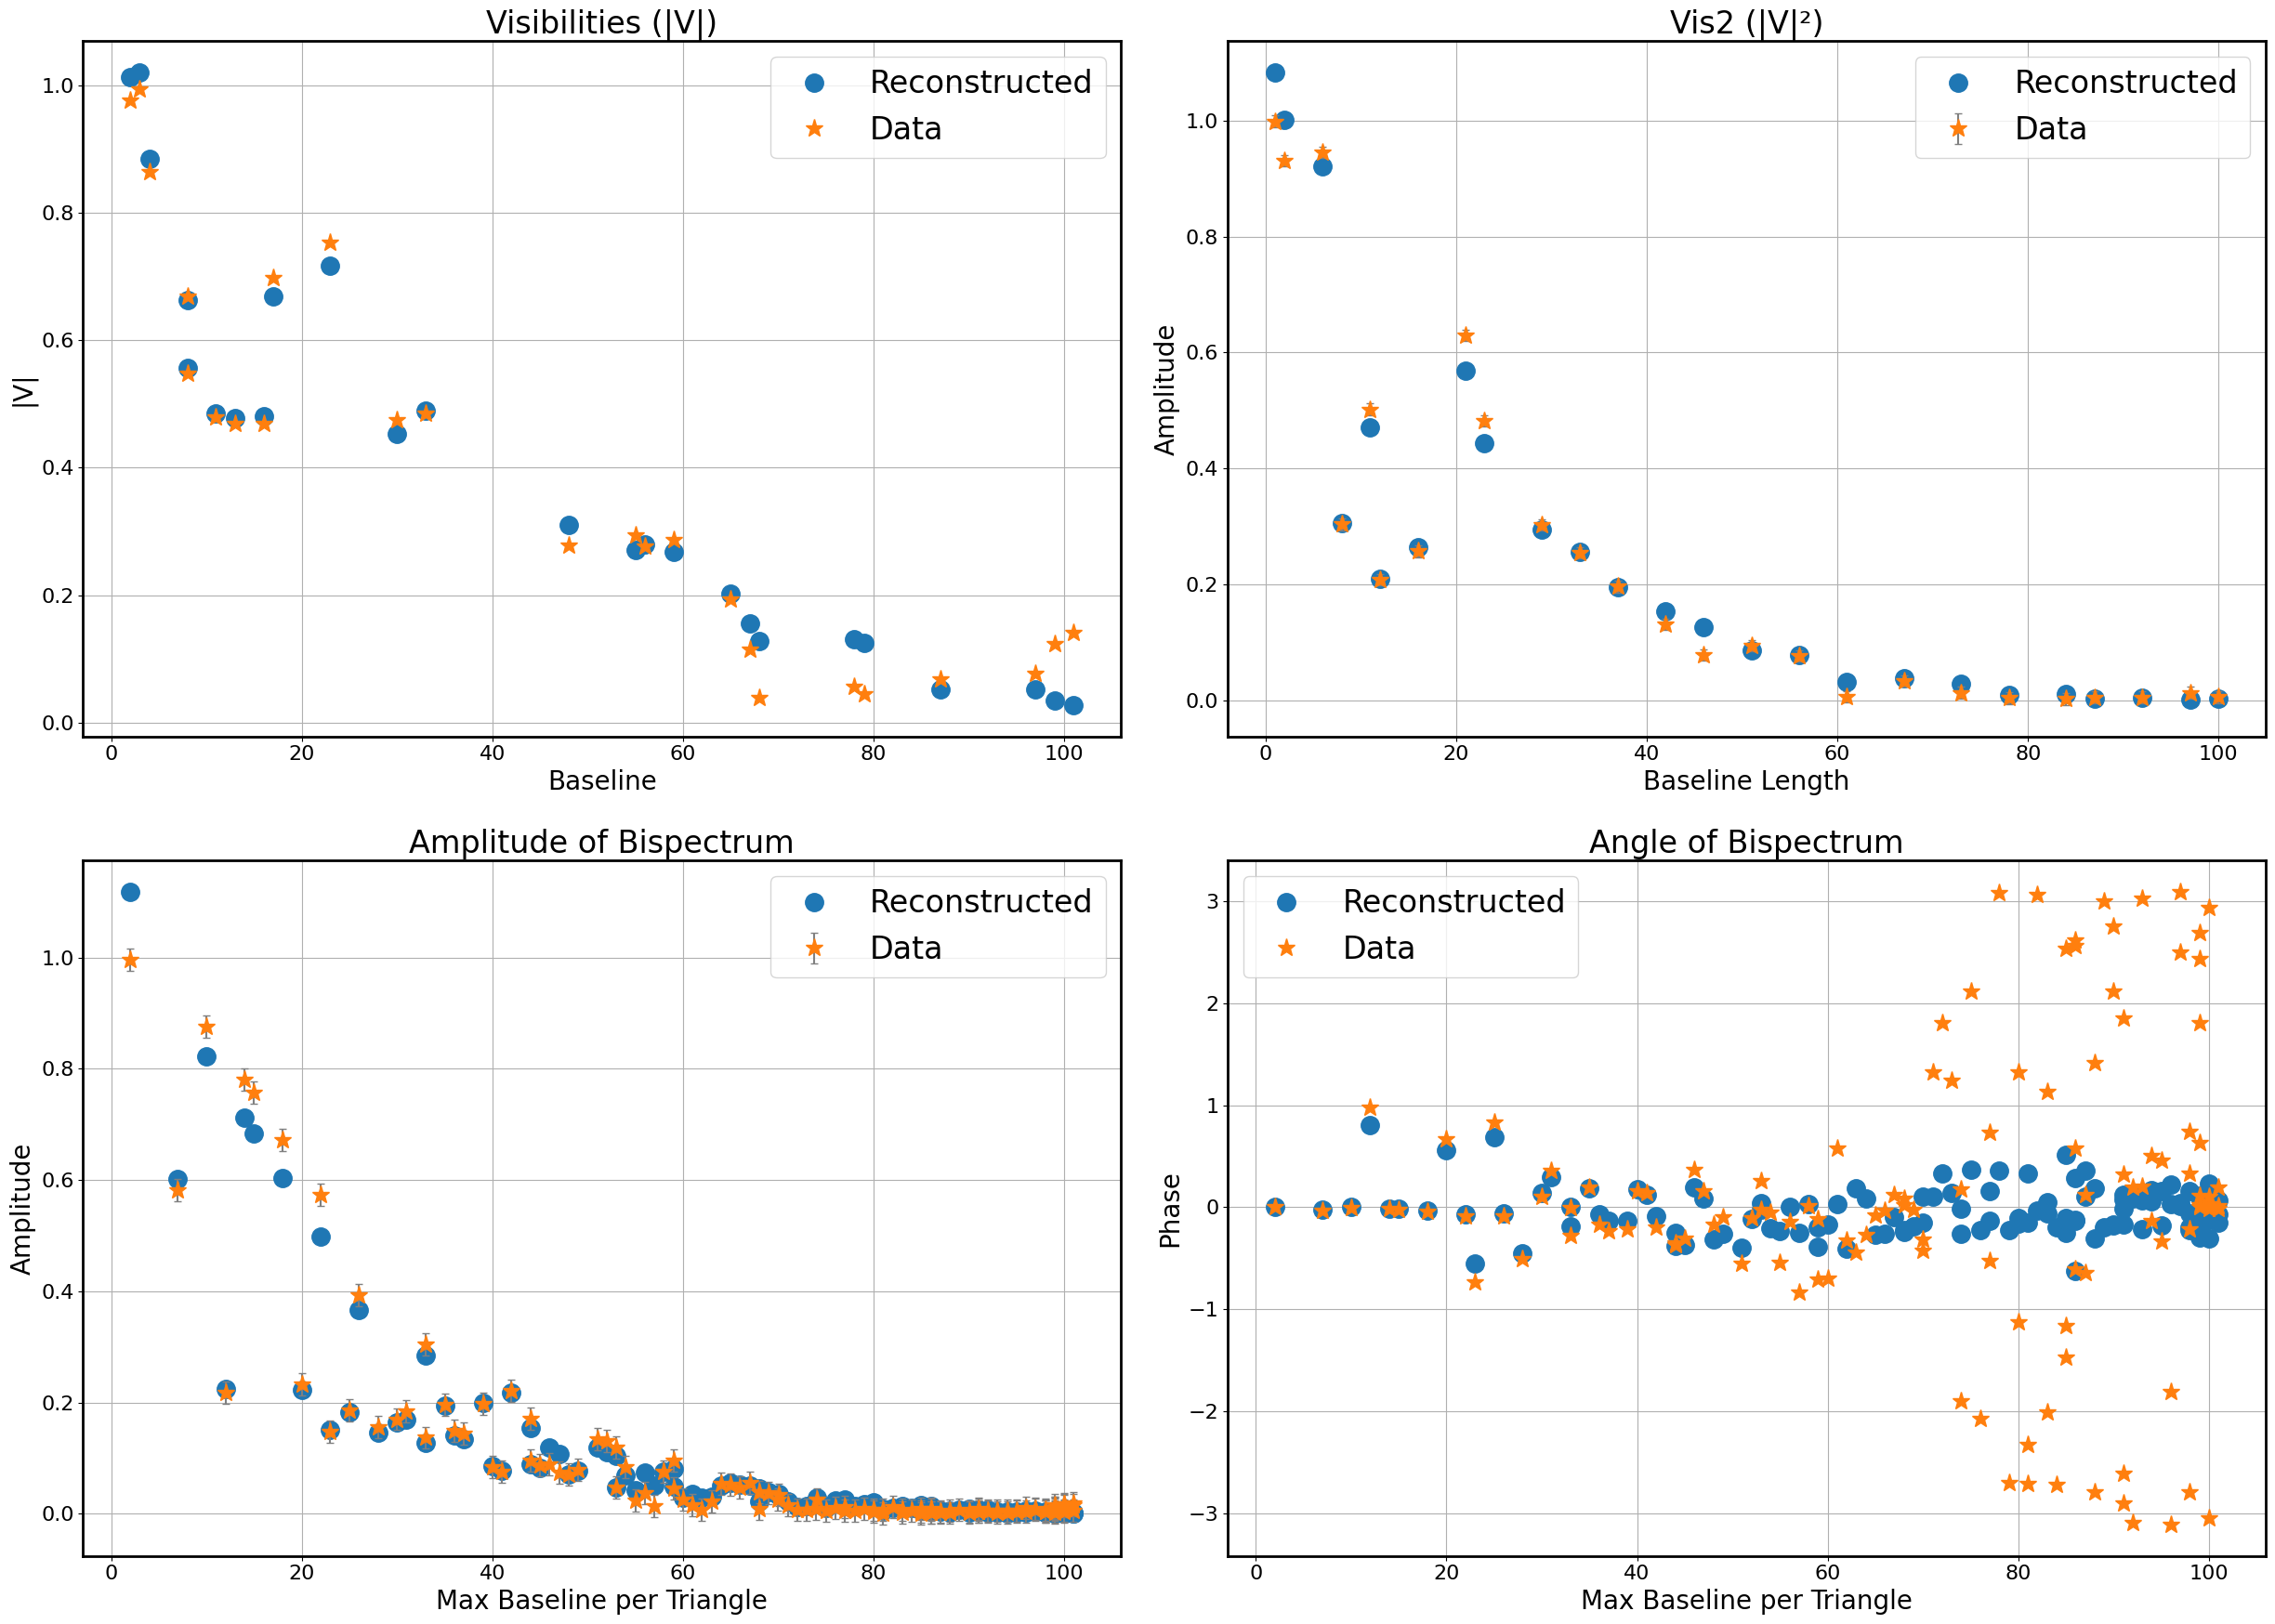

In [19]:
sigma_vis2 = 0.01
sigma_b_amp = 0.02
vis2_err = np.full(vis2_data.shape, sigma_vis2)
bisp_err = np.full((data['ncl'], 1), sigma_b_amp)

plot_model_vs_data(samples, sky_model, response_operator, vis_data, vis2_data, bisp_data, r_op1, r_op2, r_op3, data, vis2_err, bisp_err, num2=50)